## Crop Filtering TEMPO ##

lowCF, all hours version 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [2]:
crop_mask = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/0.1x0.1gridded/0.1x0.1_cropland_mask.parquet'
crop_df= pd.read_parquet(crop_mask, engine='pyarrow')

In [3]:
crop_df

,grid_lat,grid_lon,is_majority_cropland
16,35.95,-102.45,True
17,35.95,-102.35,True
19,35.95,-102.15,True
20,35.95,-102.05,True
21,35.95,-101.95,True
...,...,...,...
31398,48.95,-97.25,True
31399,48.95,-97.15,True
31400,48.95,-97.05,True
31401,48.95,-96.95,True


In [4]:
cropland_only = crop_df[crop_df['is_majority_cropland'] == True]

In [5]:
tempo_file= '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/lowCF_TEMPO_0.1x0.1_gridded_mar-jul24.parquet'
# old file #tempo_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/TEMPO_0.1x0.1_gridded_mar-jul24_all_hours.parquet'
no2_df=pd.read_parquet(tempo_file, engine='pyarrow')

In [6]:
no2_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
4,2024-03-01 13:41:26.146071,38.95,-80.05,8.335843e+14,3.157478e+14,16,7.893696e+13,0.090199,0.006510,0.284539,0.024910,0.0,0.0,0.378783
8,2024-03-01 13:41:26.146071,39.05,-80.05,1.055213e+15,5.102769e+14,20,1.141014e+14,0.092562,0.003461,0.297970,0.009242,0.0,0.0,0.483577
10,2024-03-01 13:41:26.146071,39.15,-81.25,1.277928e+15,6.824175e+14,15,1.761995e+14,0.094477,0.003371,0.291431,0.007734,0.0,0.0,0.534003
23,2024-03-01 13:41:26.146071,39.25,-80.35,2.177108e+15,1.002034e+15,14,2.678050e+14,0.095575,0.005012,0.297338,0.012624,0.0,0.0,0.460259
24,2024-03-01 13:41:26.146071,39.25,-80.25,1.692429e+15,1.336889e+15,17,3.242431e+14,0.094933,0.002528,0.296462,0.006289,0.0,0.0,0.789923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17022643,2024-07-31 23:33:15.152400,44.85,-98.55,9.127368e+14,6.625882e+14,18,1.561735e+14,0.065685,0.015345,0.219664,0.043226,0.0,0.0,0.725936
17022654,2024-07-31 23:33:15.152400,47.55,-101.55,9.091537e+14,3.799678e+14,17,9.215573e+13,0.096196,0.002519,0.264359,0.005762,0.0,0.0,0.417936
17022655,2024-07-31 23:33:15.152400,47.55,-101.45,9.734493e+14,6.972724e+14,18,1.643487e+14,0.093640,0.002055,0.258643,0.005263,0.0,0.0,0.716290
17022656,2024-07-31 23:33:15.152400,47.55,-101.35,1.145534e+15,7.579429e+14,19,1.738840e+14,0.091976,0.002376,0.254564,0.005910,0.0,0.0,0.661650


In [7]:
grid_res = 0.02

no2_df['grid_lat'] = no2_df['grid_lat'].round(2)
no2_df['grid_lon'] = no2_df['grid_lon'].round(2)
cropland_only['grid_lat'] = cropland_only['grid_lat'].round(2)
cropland_only['grid_lon'] = cropland_only['grid_lon'].round(2)

no2_cropland = pd.merge(no2_df, cropland_only[['grid_lat', 'grid_lon']], on=['grid_lat', 'grid_lon'], how='inner')

In [8]:
no2_cropland

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-03-01 14:21:31.146651,39.55,-94.85,2.398081e+15,1.554050e+15,15,4.012539e+14,0.077335,0.013126,0.225971,0.029901,0.0,0.0,0.648039
1,2024-03-01 14:21:31.146651,41.25,-94.25,1.458990e+15,7.049008e+14,15,1.820046e+14,0.057213,0.006197,0.172525,0.016454,0.0,0.0,0.483143
2,2024-03-01 14:21:31.146651,41.55,-93.45,2.961572e+15,2.299921e+15,14,6.146796e+14,0.075453,0.012609,0.214683,0.028334,0.0,0.0,0.776588
3,2024-03-01 14:21:31.146651,41.65,-93.45,2.663766e+15,1.418604e+15,13,3.934500e+14,0.071391,0.012202,0.205748,0.030036,0.0,0.0,0.532556
4,2024-03-01 14:21:31.146651,41.65,-93.35,3.190018e+15,1.837509e+15,21,4.009774e+14,0.044535,0.026033,0.130932,0.068417,0.0,0.0,0.576018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3397009,2024-07-31 23:33:15.152400,43.75,-97.95,1.226792e+15,7.884975e+14,13,2.186899e+14,0.033057,0.025854,0.109373,0.074656,0.0,0.0,0.642731
3397010,2024-07-31 23:33:15.152400,43.75,-97.85,1.067047e+15,7.917712e+14,24,1.616196e+14,0.020792,0.009943,0.078556,0.035800,0.0,0.0,0.742021
3397011,2024-07-31 23:33:15.152400,43.85,-97.85,1.196948e+15,3.982585e+14,17,9.659187e+13,0.059991,0.025293,0.197631,0.069684,0.0,0.0,0.332728
3397012,2024-07-31 23:33:15.152400,44.85,-98.55,9.127368e+14,6.625882e+14,18,1.561735e+14,0.065685,0.015345,0.219664,0.043226,0.0,0.0,0.725936


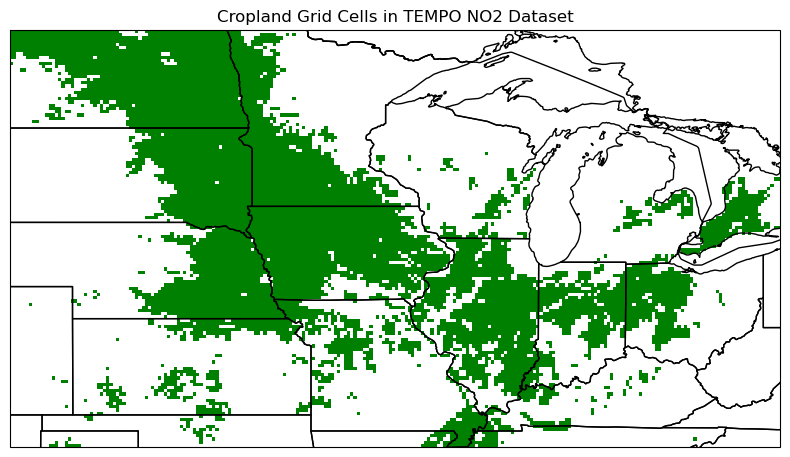

In [9]:
cropland_points = no2_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in cropland_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='green',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('Cropland Grid Cells in TEMPO NO2 Dataset')
plt.tight_layout()
plt.show()

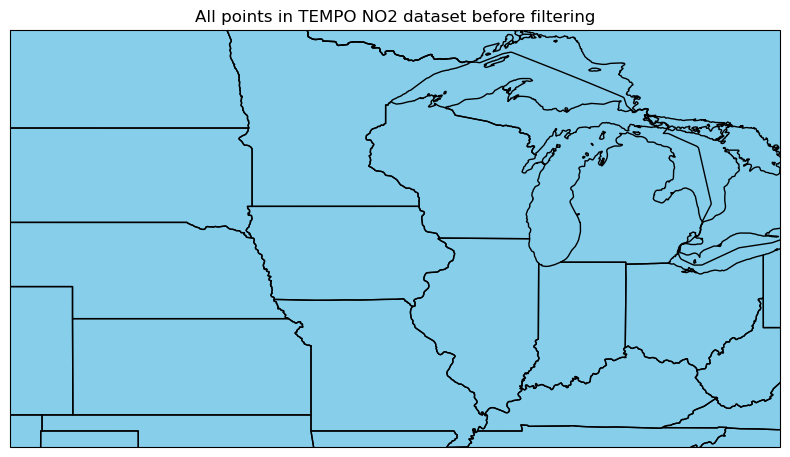

In [10]:
no2_points = no2_df[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in no2_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='skyblue',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('All points in TEMPO NO2 dataset before filtering')
plt.tight_layout()
plt.show()

In [11]:
output = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/lowCF_TEMPO_03-07_0.1x0.1GCF_all_hours.parquet'
no2_cropland.to_parquet(output, engine='pyarrow')